# ☀️💨 Day 12 · Power: where is the sun and the wind strongest?

**#30DayMapChallenge Uzbekistan 2026** · beginner tutorial, no experience needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NodiraTillayeva/30DayMapChallengeUzbekistan/blob/main/2026/Day%2012%20Power/tutorial/day12_sun_and_wind.ipynb)

In this notebook you will:
1. open **raster** maps of solar power and wind speed from the World Bank's Global Solar Atlas and Global Wind Atlas,
2. put Uzbekistan's **power plants** from OpenStreetMap on top,
3. check if the new **solar and wind farms** were built in the best places,
4. find the **sunniest and windiest regions**,
5. save a map for your post.

Run the cells from top to bottom: click a cell, then press **Shift + Enter**.

## Step 0 · Get ready

Two new tools today:
- **rasterio** opens raster files (pictures where every pixel is a number),
- **rasterstats** sums up a raster inside each region.

Colab doesn't have them yet, so the first line installs them (about 20 seconds).

In [2]:
!pip -q install rasterio rasterstats

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.plot import plotting_extent
from rasterstats import zonal_stats
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/NodiraTillayeva/30DayMapChallengeUzbekistan/main/2026/Day%2012%20Power/tutorial/data/"

print("Ready! ✅")

Ready! ✅


## Step 1 · The regions of Uzbekistan

The same 14 regions as on Day 02. We'll draw their borders on top of every map.

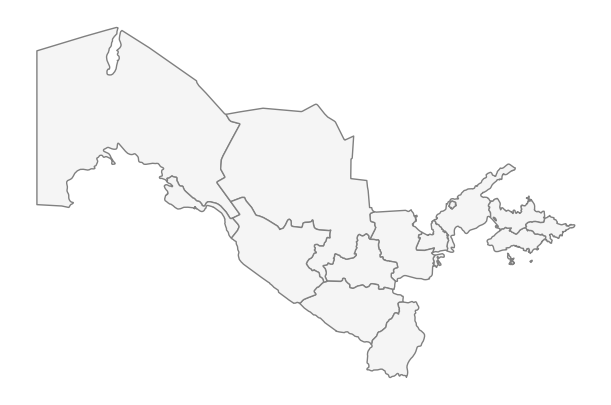

In [3]:
regions = gpd.read_file(BASE + "uzbekistan_regions.geojson")
regions.plot(color="whitesmoke", edgecolor="grey", figsize=(9, 5))
plt.axis("off")
plt.show() 

## Step 2 · Solar power

`solar_pvout.tif` comes from the **Global Solar Atlas**. Each pixel is about 1 km × 1 km and stores one number, **PVOUT**: how many **kWh** of electricity **1 kWp** of solar panels (about 2–3 big panels) makes in one year at that place.

Pixels outside Uzbekistan are empty (`nan`, "not a number").

In [4]:
solar = rasterio.open(BASE + "solar_pvout.tif")
sun = solar.read(1)

print("Size:", solar.width, "×", solar.height, "pixels")
print("Lowest: ", np.nanmin(sun), "kWh per kWp per year")
print("Highest:", np.nanmax(sun))
print("Average:", round(np.nanmean(sun))) 

Size: 2059 × 1006 pixels
Lowest:  939.0 kWh per kWp per year
Highest: 1772.0
Average: 1551


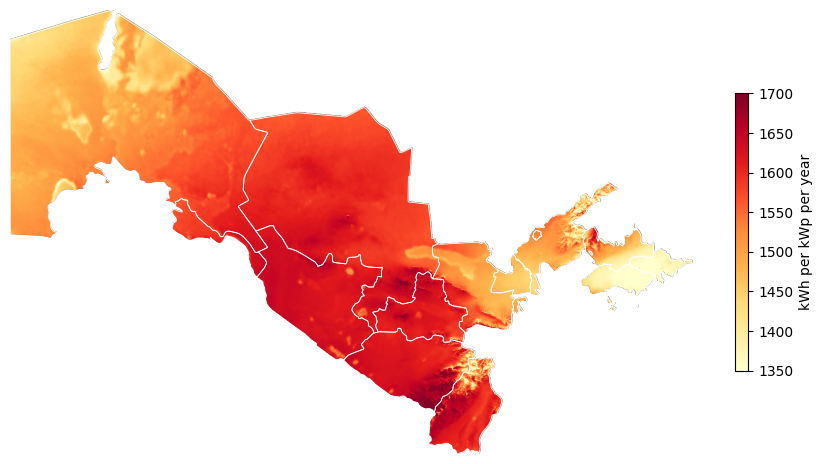

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
img = ax.imshow(sun, extent=plotting_extent(solar), cmap="YlOrRd", vmin=1350, vmax=1700)
regions.boundary.plot(ax=ax, color="white", linewidth=0.6)
fig.colorbar(img, ax=ax, shrink=0.6, label="kWh per kWp per year")
ax.set_axis_off()
plt.show() 

## Step 3 · Wind

`wind_speed_100m.tif` comes from the **Global Wind Atlas**: the average wind speed, in **metres per second**, 100 m above the ground, where the blades of a big wind turbine turn. Wind farms need about **6–7 m/s** or more.

Average wind: 6.5 m/s · strongest: 11.9 m/s


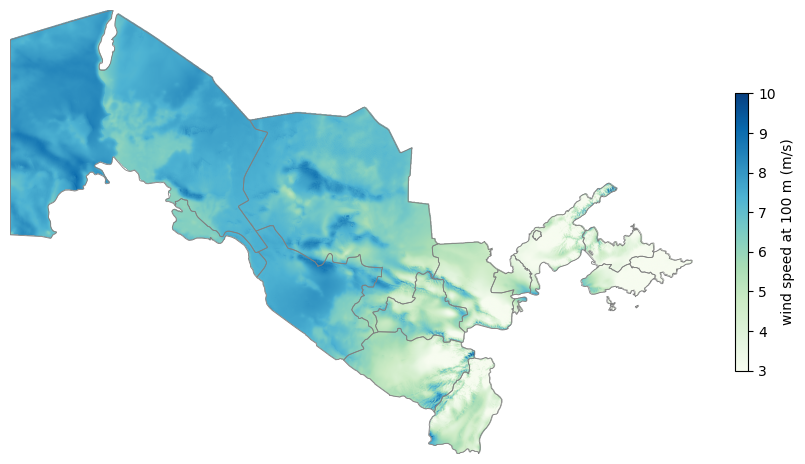

In [8]:
wind = rasterio.open(BASE + "wind_speed_100m.tif")
ws = wind.read(1)
print("Average wind:", round(np.nanmean(ws), 1), "m/s · strongest:", np.nanmax(ws), "m/s")

fig, ax = plt.subplots(figsize=(11, 6))
img = ax.imshow(ws, extent=plotting_extent(wind), cmap="GnBu", vmin=3, vmax=10)
regions.boundary.plot(ax=ax, color="grey", linewidth=0.6)
fig.colorbar(img, ax=ax, shrink=0.6, label="wind speed at 100 m (m/s)")
ax.set_axis_off() 
plt.show() 

## Step 4 · Power plants

`power_plants.geojson` holds Uzbekistan's power plants from **OpenStreetMap**: name, source (`gas`, `hydro`, `solar`, `wind`, `coal`, `nuclear`) and power in **MW** (megawatts), when it's known.

1 MW = 1000 kW. A 500 MW solar farm covers about 10 km².

In [9]:
plants = gpd.read_file(BASE + "power_plants.geojson")
print(plants["source"].value_counts()) 
plants.sort_values("mw", ascending=False).head(10) 

source
solar      99
hydro      61
gas        19
wind        5
coal        4
nuclear     1
Name: count, dtype: int64


,name,source,mw,geometry
19,Syrdarya Thermal Power Plant,gas,3000.0,POINT (69.10034 40.22823)
0,Tashkent Thermal Power Plant,gas,2230.0,POINT (69.36912 41.38201)
24,Novo-Angren power station,coal,2100.0,POINT (69.81373 40.92244)
111,Jizzakh nuclear power plant construction site,nuclear,2100.0,POINT (67.35058 40.58631)
8,Talimardjan Power Plant,gas,1700.0,POINT (65.62907 38.47986)
112,Surkhandarya power plant 1560MW,gas,1560.0,POINT (67.25186 37.37735)
58,Shirin Combined Cycle Power Plant,gas,1500.0,POINT (69.11071 40.23731)
12,Navoi Thermal Power Plant,gas,1250.0,POINT (65.31439 40.15804)
33,Turakurgan power plant,gas,900.0,POINT (71.45846 40.9966)
30,Takhiatash Thermal Power Plant,gas,730.0,POINT (59.55496 42.31638)


## Step 5 · Are the farms in the right places?

Now we put the **solar farms** on the solar map and the **wind farms** on the wind map. A bigger circle means more MW.

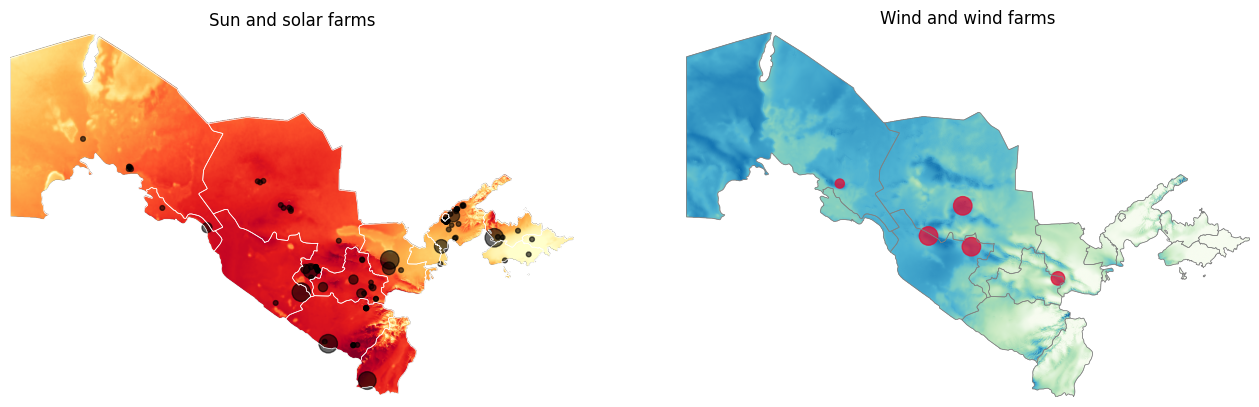

In [10]:
solar_farms = plants[plants["source"] == "solar"]
wind_farms = plants[plants["source"] == "wind"]

def size(mw):
    return 10 + mw.fillna(5) / 3      # unknown MW → a small circle

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.imshow(sun, extent=plotting_extent(solar), cmap="YlOrRd", vmin=1350, vmax=1700)
regions.boundary.plot(ax=ax1, color="white", linewidth=0.5)
solar_farms.plot(ax=ax1, markersize=size(solar_farms["mw"]), color="black", alpha=0.6)
ax1.set_title("Sun and solar farms")

ax2.imshow(ws, extent=plotting_extent(wind), cmap="GnBu", vmin=3, vmax=10)
regions.boundary.plot(ax=ax2, color="grey", linewidth=0.5)
wind_farms.plot(ax=ax2, markersize=size(wind_farms["mw"]), color="crimson", alpha=0.8)
ax2.set_title("Wind and wind farms")

for ax in (ax1, ax2):
    ax.set_axis_off() 
plt.show()

Let's measure it. `sample()` reads the raster value **under each farm**. Then we compare it with the whole country: "better than 80%" means only 20% of Uzbekistan is sunnier (or windier).

In [11]:
def better_than(value, grid):
    values = grid[~np.isnan(grid)]
    return round(100 * (values < value).mean()) 

big_solar = solar_farms[solar_farms["mw"] >= 100].copy()
big_solar["pvout"] = [v[0] for v in solar.sample([(p.x, p.y) for p in big_solar.geometry])]
big_solar["better than % of Uzbekistan"] = [better_than(v, sun) for v in big_solar["pvout"]] 
big_solar[["name", "mw", "pvout", "better than % of Uzbekistan"]].sort_values("pvout", ascending=False)

,name,mw,pvout,better than % of Uzbekistan
180,Nawai Hybrid Solar Power Plant 300MW,300.0,1641.0,95
94,Nishon 500 MWh Solar farm,500.0,1641.0,95
52,Nur Navoi Solar Farm,100.0,1630.0,89
84,Buxoro QES 500MW,500.0,1629.0,88
182,Sarimay Solar Farm,126.0,1628.0,88
61,Sherobod QES 457 MW,457.0,1621.0,82
63,Samarqand QES 100MW,100.0,1621.0,82
50,Nurabad solar power plant,100.0,1618.0,80
97,Sazag'on QES 100MW,100.0,1611.0,75
62,G'allaorol QES 220 MW,220.0,1580.0,54


In [12]:
wind_farms = wind_farms.copy()
wind_farms["wind_ms"] = [v[0] for v in wind.sample([(p.x, p.y) for p in wind_farms.geometry])]
wind_farms["better than % of Uzbekistan"] = [better_than(v, ws) for v in wind_farms["wind_ms"]]
wind_farms[["name", "mw", "wind_ms", "better than % of Uzbekistan"]] 

,name,mw,wind_ms,better than % of Uzbekistan
184,Zarafshon Wind Farm 500MW,500.0,8.27,97
185,Bash Wind Farm 500MW,500.0,7.76,84
186,Dzhankeldi Wind Farm 500MW,500.0,8.64,100
187,Karatau Wind Farm 100MW,100.0,7.82,86
188,Jizzakh wind farm,250.0,6.44,35


## Step 6 · The sunniest and windiest regions

`zonal_stats` cuts the raster with each region's border and gives the **average** of the pixels inside it.

In [13]:
def region_mean(grid, raster):
    filled = np.where(np.isnan(grid), -9999, grid)
    stats = zonal_stats(regions, filled, affine=raster.transform, nodata=-9999, stats="mean")
    return [round(s["mean"], 1) for s in stats]

regions["sun"] = region_mean(sun, solar) 
regions["wind"] = region_mean(ws, wind)
regions.drop(columns="geometry").sort_values("sun", ascending=False)

,region,sun,wind
12,Bukhoro,1626.6,7.3
7,Kashkadarya,1622.1,4.9
6,Samarkand,1618.4,5.4
10,Navoi,1596.3,6.8
8,Surkhandarya,1596.2,4.2
11,Khorezm,1594.7,6.7
13,Tashkent City,1531.3,3.4
5,Jizzakh,1522.5,4.5
9,Karakalpakstan,1507.6,7.6
1,Tashkent Region,1478.4,3.7


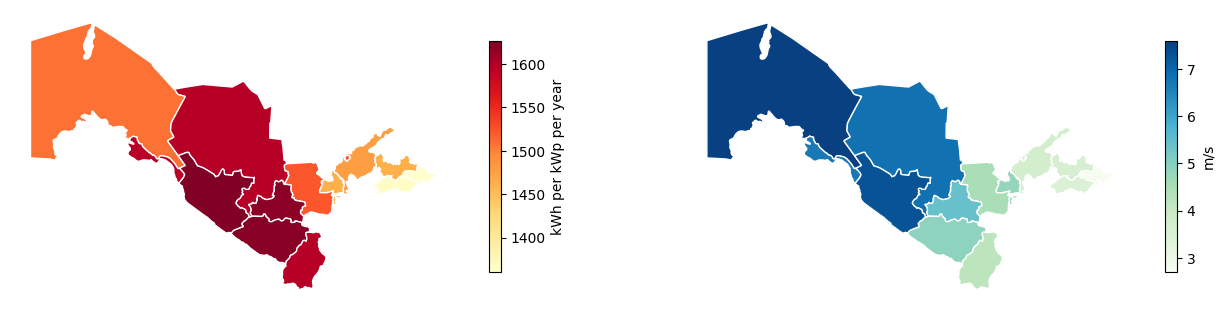

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
regions.plot(column="sun", cmap="YlOrRd", legend=True, ax=ax1, edgecolor="white",
             legend_kwds={"label": "kWh per kWp per year", "shrink": 0.6})
regions.plot(column="wind", cmap="GnBu", legend=True, ax=ax2, edgecolor="white",
             legend_kwds={"label": "m/s", "shrink": 0.6})
for ax in (ax1, ax2):
    ax.set_axis_off() 
plt.show() 

## Step 7 · Save your map

This draws the two big maps again, without titles, and saves them as **power_map.png** (high resolution). Then it downloads the file.

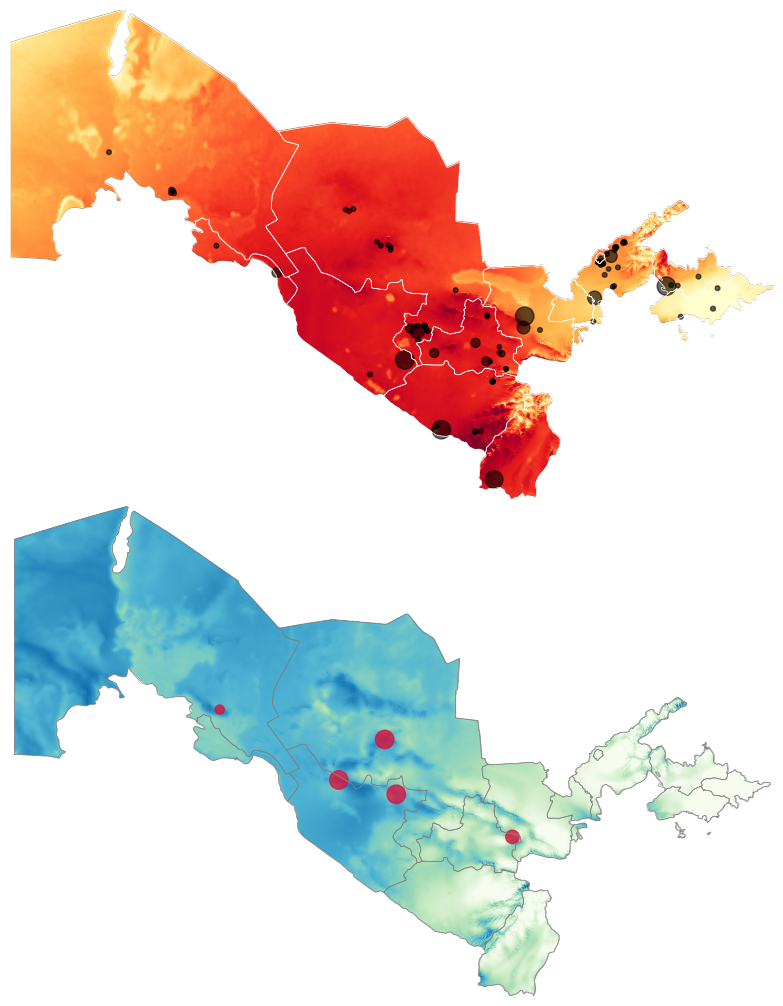

Saved to Downloads\power_map.png! ✅


In [17]:

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), facecolor="white")

ax1.imshow(sun, extent=plotting_extent(solar), cmap="YlOrRd", vmin=1350, vmax=1700)
regions.boundary.plot(ax=ax1, color="white", linewidth=0.5)
solar_farms.plot(ax=ax1, markersize=size(solar_farms["mw"]), color="black", alpha=0.6)

ax2.imshow(ws, extent=plotting_extent(wind), cmap="GnBu", vmin=3, vmax=10)
regions.boundary.plot(ax=ax2, color="grey", linewidth=0.5)
wind_farms.plot(ax=ax2, markersize=size(wind_farms["mw"]), color="crimson", alpha=0.8)

for ax in (ax1, ax2):
    ax.set_axis_off()

plt.tight_layout(pad=0.5)
plt.savefig(r"C:\Users\Asus\Downloads\power_map.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved to Downloads\\power_map.png! ✅")


## 🎉 Done!

Share your map with **#30DayMapChallenge**.

**Credits:** Global Solar Atlas 2.0 and Global Wind Atlas 3 (World Bank, Solargis, DTU, CC BY 4.0). Power plants © OpenStreetMap contributors (ODbL).